#  End-to-End Economic Intelligence Pipeline & Machine Learning
### Analisis Makroekonomi & Prediksi GDP Negara-Negara ASEAN-6 (World Bank Data)

---

##  Ringkasan Proyek
Notebook ini menyajikan **seluruh siklus proses data science dan data engineering** dari proyek ini ke dalam satu alur kerja terpadu:

1. **Arsitektur Pipeline & Airflow DAG**:
   - Struktur database relasional MySQL (`countries`, `gdp`, `population`, `unemployment`).
   - Simulasi alur kerja Apache Airflow (*Extract*, *Transform*, *Load*).
2. **Data Gathering (Ingestion / ETL)**:
   - Ekstraksi data makroekonomi langsung dari **World Bank REST API** untuk 6 negara ASEAN (*Indonesia, Malaysia, Singapura, Thailand, Filipina, Vietnam*).
   - Opsi pembacaan data dari MySQL Database dengan fallback API otomatis.
3. **Data Assessing (Audit Kualitas Data)**:
   - Pemeriksaan kelengkapan baris, deteksi duplikasi *composite key* `(country_code, year)`, dan analisis audit *missing values*.
4. **Data Cleaning & Preprocessing**:
   - Standarisasi tipe data, normalisasi nama negara, dan penanganan nilai hilang dengan **Time-Series Linear Interpolation per negara**.
5. **Exploratory Data Analysis (EDA) & Visualisasi**:
   - Statistik deskriptif, matriks korelasi Pearson, visualisasi tren pertumbuhan GDP, analisis korelasi populasi vs GDP, serta bubble plot pengangguran.
6. **Machine Learning Modeling (Random Forest Regressor)**:
   - Pelatihan model prediktif GDP dengan **Time-Aware Train-Test Split** (evaluasi pada 3 tahun terakhir untuk mencegah *lookahead bias*).
   - One-Hot Encoding kategori negara.
   - Evaluasi metrik performa: $R^2$, MAE, RMSE, analisis residual error, serta *Feature Importance*.
7. **Kesimpulan & Rekomendasi Kebijakan**:
   - Sintesis otomatis temuan utama dan rekomendasi strategis makroekonomi.


In [1]:
# =============================================================================
# 1. SETUP ENVIRONMENT & IMPORT LIBRARIES
# =============================================================================
import os
import sys
import json
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Nonaktifkan warning agar notebook tetap rapi
warnings.filterwarnings('ignore')

# Konfigurasi Tampilan Grafik Visualisasi Modern
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['figure.autolayout'] = True

print(f"✅ Python Environment   : Ready ({sys.version.split()[0]})")
print(f"✅ Pandas Version       : {pd.__version__}")
print(f"✅ Scikit-Learn Version : Ready")
print(f"✅ Matplotlib & Seaborn : Ready")


✅ Python Environment   : Ready (3.13.2)
✅ Pandas Version       : 2.2.3
✅ Scikit-Learn Version : Ready
✅ Matplotlib & Seaborn : Ready


In [2]:
# =============================================================================
# 2. KONFIGURASI PARAMETER, NEGARA ASEAN, DAN INDIKATOR
# =============================================================================
COUNTRY_MAP = {
    "IDN": "Indonesia",
    "MYS": "Malaysia",
    "SGP": "Singapore",
    "THA": "Thailand",
    "PHL": "Philippines",
    "VNM": "Vietnam"
}

# World Bank Open Data Indicator Codes
INDICATORS = {
    "gdp": "NY.GDP.MKTP.CD",          # GDP Nominal (current US$)
    "population": "SP.POP.TOTL",       # Total Population
    "unemployment": "SL.UEM.TOTL.ZS"   # Unemployment Rate (% of total labor force)
}

NUMERIC_COLUMNS = ["gdp", "population", "unemployment_rate"]

# Palet warna konsisten untuk masing-masing negara
COUNTRY_COLORS = {
    "Indonesia": "#0284C7",    # Sky Blue
    "Malaysia": "#EAB308",     # Gold
    "Singapore": "#EF4444",    # Coral Red
    "Thailand": "#10B981",     # Emerald Green
    "Philippines": "#8B5CF6",  # Purple
    "Vietnam": "#F97316"       # Orange
}

print("Daftar 6 Negara ASEAN yang Dianalisis:")
for code, name in COUNTRY_MAP.items():
    print(f" • [{code}] : {name}")


Daftar 6 Negara ASEAN yang Dianalisis:
 • [IDN] : Indonesia
 • [MYS] : Malaysia
 • [SGP] : Singapore
 • [THA] : Thailand
 • [PHL] : Philippines
 • [VNM] : Vietnam


---
##  Bagian 1: Arsitektur Pipeline Apache Airflow & Schema MySQL
Dalam arsitektur *production* di repository ini (`dags/etl_economic_to_mysql.py`), orkestrasi data dijalankan secara terjadwal menggunakan **Apache Airflow**.

### 1. Skema Database Relasional (DDL MySQL):
Tabel dinormalisasi untuk menjaga integritas data relasional:
- `countries`: Master tabel daftar negara (`country_id`, `country_code`, `country_name`).
- `gdp`: Menyimpan nilai GDP per negara per tahun (`country_code`, `year`, `gdp`, `country_id`).
- `population`: Menyimpan populasi tahunan (`country_code`, `year`, `population`, `country_id`).
- `unemployment`: Menyimpan tingkat pengangguran tahunan (`country_code`, `year`, `unemployment_rate`, `country_id`).

### 2. Alur Tugas Airflow (*Task Dependency*):
```text
[create_tables] >> [extract_economic_data] >> [transform_economic_data] >> [load_economic_data]
```


In [3]:
# Representasi DDL Skema Relasional MySQL (seperti yang dieksekusi di Airflow DAG)
MYSQL_SCHEMA_SQL = """
CREATE TABLE IF NOT EXISTS countries (
    country_id INT AUTO_INCREMENT PRIMARY KEY,
    country_code VARCHAR(3) NOT NULL UNIQUE,
    country_name VARCHAR(100) NOT NULL
);

CREATE TABLE IF NOT EXISTS gdp (
    id INT AUTO_INCREMENT PRIMARY KEY,
    country_code VARCHAR(3) NOT NULL,
    country_id INT NULL,
    year INT NOT NULL,
    gdp DOUBLE,
    UNIQUE KEY unique_country_year (country_code, year),
    CONSTRAINT fk_gdp_country FOREIGN KEY (country_id) REFERENCES countries(country_id)
);

CREATE TABLE IF NOT EXISTS population (
    id INT AUTO_INCREMENT PRIMARY KEY,
    country_code VARCHAR(3) NOT NULL,
    country_id INT NULL,
    year INT NOT NULL,
    population BIGINT,
    UNIQUE KEY unique_country_year (country_code, year),
    CONSTRAINT fk_population_country FOREIGN KEY (country_id) REFERENCES countries(country_id)
);

CREATE TABLE IF NOT EXISTS unemployment (
    id INT AUTO_INCREMENT PRIMARY KEY,
    country_code VARCHAR(3) NOT NULL,
    country_id INT NULL,
    year INT NOT NULL,
    unemployment_rate DOUBLE,
    UNIQUE KEY unique_country_year (country_code, year),
    CONSTRAINT fk_unemployment_country FOREIGN KEY (country_id) REFERENCES countries(country_id)
);
"""

print("✅ Skema database relational siap direferensikan.")


✅ Skema database relational siap direferensikan.


---
##  Bagian 2: Data Gathering (Ingestion dari World Bank REST API)
Data ditarik secara dinamis dari **World Bank REST API** dengan menggabungkan kode ISO 6 negara menjadi satu panggilan query per indikator (`per_page=20000`).
Hal ini memaksimalkan efisiensi jaringan dan memastikan seluruh rentang data historis (dari 1960 hingga tahun terakhir) tertangkap.


In [4]:
def gather_data_from_world_bank(country_map=COUNTRY_MAP, indicators=INDICATORS):
    """
    Ekstraksi data makroekonomi langsung dari World Bank REST API.
    """
    countries_param = ";".join(country_map.keys())
    data_dict = {}
    session = requests.Session()

    print("Mengunduh data indikator dari World Bank API...")
    for name, indicator_code in indicators.items():
        url = (
            f"https://api.worldbank.org/v2/country/{countries_param}/"
            f"indicator/{indicator_code}?format=json&per_page=20000"
        )
        print(f" -> Mengambil: {name.upper():<15} [URL: {url[:60]}...]")
        try:
            response = session.get(url, timeout=30)
            response.raise_for_status()
            payload = response.json()
            
            if not isinstance(payload, list) or len(payload) < 2 or not payload[1]:
                print(f"    [Peringatan] Response kosong untuk {name}")
                continue

            records = payload[1]
            print(f"    Berhasil mengambil {len(records)} records.")
            
            for item in records:
                country_code = item.get("countryiso3code")
                year_value = item.get("date")
                if not country_code or not year_value:
                    continue
                try:
                    year_int = int(year_value)
                    key = (country_code, year_int)
                    row = data_dict.setdefault(
                        key,
                        {"country_code": country_code, "year": year_int}
                    )
                    column = "unemployment_rate" if name == "unemployment" else name
                    val = item.get("value")
                    row[column] = float(val) if val is not None else np.nan
                except (TypeError, ValueError):
                    continue
        except Exception as e:
            print(f"    [Error] Gagal saat mengambil {name}: {e}")

    df = pd.DataFrame(list(data_dict.values()))
    for col in NUMERIC_COLUMNS:
        if col not in df.columns:
            df[col] = np.nan

    if not df.empty:
        df = df.sort_values(["country_code", "year"]).reset_index(drop=True)
    
    return df

# Eksekusi proses gathering
raw_df = gather_data_from_world_bank()
print(f"\n✅ Data Gathering Sukses! Total baris mentah: {len(raw_df)} baris.")
raw_df.head(10)


Mengunduh data indikator dari World Bank API...
 -> Mengambil: GDP             [URL: https://api.worldbank.org/v2/country/IDN;MYS;SGP;THA;PHL;VNM...]
    Berhasil mengambil 396 records.
 -> Mengambil: POPULATION      [URL: https://api.worldbank.org/v2/country/IDN;MYS;SGP;THA;PHL;VNM...]
    Berhasil mengambil 396 records.
 -> Mengambil: UNEMPLOYMENT    [URL: https://api.worldbank.org/v2/country/IDN;MYS;SGP;THA;PHL;VNM...]
    Berhasil mengambil 396 records.

✅ Data Gathering Sukses! Total baris mentah: 396 baris.


,country_code,year,gdp,population,unemployment_rate
0,IDN,1960,NaN,88296070.0,NaN
1,IDN,1961,NaN,90791249.0,NaN
2,IDN,1962,NaN,93375850.0,NaN
3,IDN,1963,NaN,96051424.0,NaN
4,IDN,1964,NaN,98833749.0,NaN
5,IDN,1965,NaN,101365130.0,NaN
6,IDN,1966,NaN,103792754.0,NaN
7,IDN,1967,5.667757e+09,106526393.0,NaN
8,IDN,1968,7.076465e+09,109450006.0,NaN
9,IDN,1969,8.337423e+09,112517639.0,NaN


---
##  Bagian 3: Data Assessing (Audit Integritas & Kualitas Data)
Sebelum data digunakan untuk analisis atau pemodelan, kita melakukan penilaian menyeluruh (*data health check*):
1. **Total Records & Dimensi Dataset**.
2. **Pemeriksaan Duplikasi**: Memeriksa apakah terdapat baris duplikat berdasarkan composite key `(country_code, year)`.
3. **Analisis Nilai Hilang (Missing Values)**: Mengidentifikasi indikator mana yang memiliki gap waktu paling tinggi.
4. **Visualisasi Audit Kelengkapan Data**.


In [5]:
def assess_data(df):
    """
    Laporan audit kelengkapan dan kesehatan data.
    """
    total_rows = len(df)
    missing_counts = df.isnull().sum()
    missing_pct = (missing_counts / total_rows * 100).round(2)
    
    missing_report = pd.DataFrame({
        "Jumlah Nilai Hilang": missing_counts,
        "Persentase (%)": missing_pct
    })
    
    dup_rows = int(df.duplicated().sum())
    dup_composite = int(df.duplicated(subset=["country_code", "year"]).sum())
    
    min_year = int(df["year"].min()) if "year" in df and total_rows else None
    max_year = int(df["year"].max()) if "year" in df and total_rows else None
    
    print("=" * 65)
    print("LAPORAN DATA ASSESSING (AUDIT KUALITAS DATA)")
    print("=" * 65)
    print(f"• Total Observasi (Baris)       : {total_rows}")
    print(f"• Total Kolom                   : {len(df.columns)}")
    print(f"• Rentang Tahun Observasi       : {min_year} s/d {max_year}")
    print(f"• Duplikasi Baris Lengkap       : {dup_rows}")
    print(f"• Duplikasi Kunci (Negara, Thn) : {dup_composite}")
    print("-" * 65)
    print("Rincian Missing Values per Kolom:")
    display(missing_report)
    
    return missing_report

missing_report = assess_data(raw_df)


LAPORAN DATA ASSESSING (AUDIT KUALITAS DATA)
• Total Observasi (Baris)       : 396
• Total Kolom                   : 5
• Rentang Tahun Observasi       : 1960 s/d 2025
• Duplikasi Baris Lengkap       : 0
• Duplikasi Kunci (Negara, Thn) : 0
-----------------------------------------------------------------
Rincian Missing Values per Kolom:


,Jumlah Nilai Hilang,Persentase (%)
country_code,0,0.00
year,0,0.00
gdp,32,8.08
population,0,0.00
unemployment_rate,186,46.97


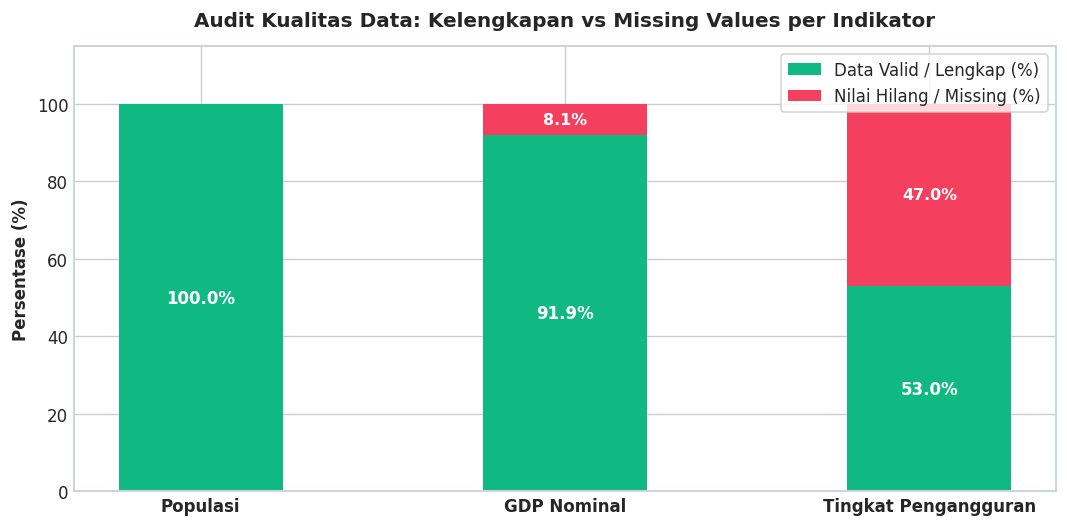

In [6]:
# Visualisasi Kelengkapan Data vs Missing Values (Stacked Bar Chart)
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)

total_len = len(raw_df)
pop_valid = (raw_df["population"].notnull().sum() / total_len) * 100
gdp_valid = (raw_df["gdp"].notnull().sum() / total_len) * 100
unemp_valid = (raw_df["unemployment_rate"].notnull().sum() / total_len) * 100

indicators = ["Populasi", "GDP Nominal", "Tingkat Pengangguran"]
valid_pcts = [pop_valid, gdp_valid, unemp_valid]
missing_pcts = [100 - v for v in valid_pcts]

x = np.arange(len(indicators))
width = 0.45

b1 = ax.bar(x, valid_pcts, width, label="Data Valid / Lengkap (%)", color="#10B981")
b2 = ax.bar(x, missing_pcts, width, bottom=valid_pcts, label="Nilai Hilang / Missing (%)", color="#F43F5E")

for i, v in enumerate(valid_pcts):
    ax.text(i, v / 2, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    if missing_pcts[i] > 5:
        ax.text(i, v + missing_pcts[i] / 2, f"{missing_pcts[i]:.1f}%", ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")

ax.set_title("Audit Kualitas Data: Kelengkapan vs Missing Values per Indikator", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Persentase (%)", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(indicators, fontweight="bold", fontsize=10)
ax.set_ylim(0, 115)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


---
##  Bagian 4: Data Cleaning & Preprocessing
Berdasarkan hasil audit, dilakukan langkah-langkah pembersihan:
1. **Deduplikasi**: Memastikan tiap kombinasi `country_code` dan `year` unik.
2. **Pemetaan Nama Negara**: Menambahkan kolom `country` lengkap dari kode ISO-3.
3. **Penyelarasan Tipe Data**:
   - `year`: integer
   - `gdp`, `population`, `unemployment_rate`: numeric float
4. **Time-Series Linear Interpolation (Per Negara)**:
   - Nilai hilang pada indikator makroekonomi diisi menggunakan interpolasi linear deret waktu **secara independen di dalam masing-masing negara** (`df.groupby('country_code')[col].interpolate(...)`).
   - Pendekatan ini menjaga tren spesifik tiap negara tanpa mencampur data antar batas negara.
5. **Feature Engineering Awal**:
   - Menghitung `gdp_trillion` (dalam Triliun USD) dan `gdp_per_capita`.


In [7]:
def clean_data(df, country_map=COUNTRY_MAP):
    """
    Membersihkan data dan melakukan imputasi deret waktu linear per negara.
    """
    cleaned_df = df.copy()
    clean_log = []
    
    # 1. Hapus duplikasi
    initial_len = len(cleaned_df)
    cleaned_df = cleaned_df.drop_duplicates(subset=["country_code", "year"]).reset_index(drop=True)
    dups_removed = initial_len - len(cleaned_df)
    if dups_removed:
        clean_log.append(f"Menghapus {dups_removed} duplikasi.")
    
    # 2. Tambah kolom nama negara
    cleaned_df["country"] = cleaned_df["country_code"].map(country_map).fillna(cleaned_df["country_code"])
    clean_log.append("Menambahkan nama negara lengkap dari kode ISO-3.")
    
    # 3. Penyelarasan tipe data
    cleaned_df["year"] = pd.to_numeric(cleaned_df["year"], errors="coerce")
    for col in NUMERIC_COLUMNS:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col], errors="coerce")
        
    cleaned_df = cleaned_df.dropna(subset=["country_code", "year"])
    cleaned_df["year"] = cleaned_df["year"].astype(int)
    cleaned_df = cleaned_df.sort_values(["country_code", "year"]).reset_index(drop=True)
    
    # 4. Interpolasi linear per negara
    for col in NUMERIC_COLUMNS:
        cleaned_df[col] = cleaned_df.groupby("country_code", sort=False)[col].transform(
            lambda s: s.interpolate(method="linear", limit_direction="both")
        )
    clean_log.append("Melakukan interpolasi deret waktu linear terisolasi per negara.")
    
    # 5. Drop sisa data yang tidak memiliki nilai GDP
    before_drop = len(cleaned_df)
    cleaned_df = cleaned_df.dropna(subset=["gdp"]).reset_index(drop=True)
    dropped = before_drop - len(cleaned_df)
    if dropped:
        clean_log.append(f"Menghapus {dropped} baris tanpa nilai GDP setelah interpolasi.")
        
    # 6. Feature Engineering
    cleaned_df["gdp_trillion"] = cleaned_df["gdp"] / 1e12
    cleaned_df["gdp_per_capita"] = cleaned_df["gdp"] / cleaned_df["population"]
    
    return cleaned_df, clean_log

cleaned_df, clean_log = clean_data(raw_df)

print("=" * 60)
print("LOG AKTIVITAS DATA CLEANING:")
print("=" * 60)
for log in clean_log:
    print(f" ✔ {log}")

print(f"\n✅ Data Berhasil Dibersihkan: {len(cleaned_df)} baris siap dianalisis.")
cleaned_df.sample(5, random_state=42)


LOG AKTIVITAS DATA CLEANING:
 ✔ Menambahkan nama negara lengkap dari kode ISO-3.
 ✔ Melakukan interpolasi deret waktu linear terisolasi per negara.

✅ Data Berhasil Dibersihkan: 396 baris siap dianalisis.


,country_code,year,gdp,population,unemployment_rate,country,gdp_trillion,gdp_per_capita
78,MYS,1972,5.043347e+09,10676835.0,3.700,Malaysia,0.005043,472.363509
277,THA,1973,1.083859e+10,38947787.0,2.630,Thailand,0.010839,278.285063
250,SGP,2012,2.950929e+11,5312437.0,3.720,Singapore,0.295093,55547.555308
55,IDN,2015,8.608542e+11,261799249.0,4.514,Indonesia,0.860854,3288.222697
391,VNM,2021,3.664748e+11,98935098.0,2.383,Vietnam,0.366475,3704.193559


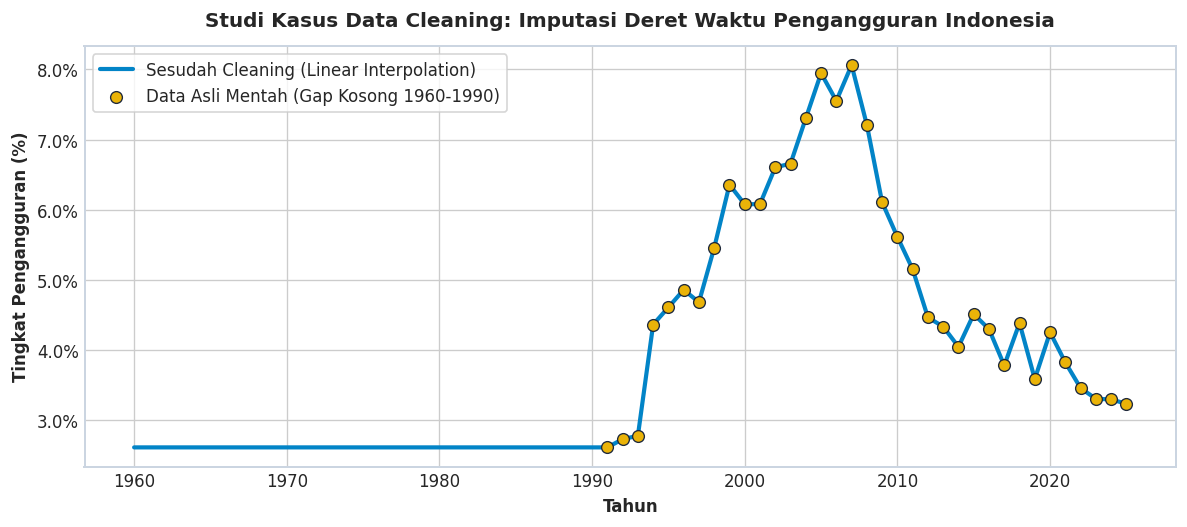

In [8]:
# Visualisasi Studi Kasus: Sebelum vs Sesudah Imputasi Deret Waktu (Indonesia)
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)

idn_clean = cleaned_df[cleaned_df["country_code"] == "IDN"].sort_values("year")
idn_raw = raw_df[raw_df["country_code"] == "IDN"].sort_values("year")

# Garis hasil interpolasi
ax.plot(idn_clean["year"], idn_clean["unemployment_rate"], color="#0284C7", linewidth=2.5,
        label="Sesudah Cleaning (Linear Interpolation)", zorder=2)

# Titik asli data mentah World Bank
raw_valid = idn_raw.dropna(subset=["unemployment_rate"])
ax.scatter(raw_valid["year"], raw_valid["unemployment_rate"], color="#EAB308", s=50,
           label="Data Asli Mentah (Gap Kosong 1960-1990)", zorder=3, edgecolors="#1E293B", linewidth=0.8)

ax.set_title("Studi Kasus Data Cleaning: Imputasi Deret Waktu Pengangguran Indonesia", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tahun", fontweight="bold")
ax.set_ylabel("Tingkat Pengangguran (%)", fontweight="bold")
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f%%"))
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


---
##  Bagian 5: Exploratory Data Analysis (EDA) & Analisis Korelasi
Pada tahap ini kita mengevaluasi pola-pola ekonomi makro utama:
1. **Statistik Deskriptif**: Memahami sebaran, median, kuartil, dan variansi nilai variabel.
2. **Korelasi Pearson**: Menilai keterkaitan linear antara Tahun, Populasi, Pengangguran, dan GDP.
3. **Tren Pertumbuhan GDP**: Mengamati akselerasi ekonomi ASEAN dari dekade ke dekade.
4. **Hubungan Skala Demografi vs Output Ekonomi**: Seberapa besar populasi mendorong GDP agregat.


In [9]:
# Statistik Deskriptif Variabel
desc = cleaned_df[["gdp_trillion", "population", "unemployment_rate", "gdp_per_capita"]].describe().T
desc["mean"] = desc["mean"].round(2)
desc["std"] = desc["std"].round(2)
desc["min"] = desc["min"].round(2)
desc["max"] = desc["max"].round(2)

print("Tabel Statistik Deskriptif:")
display(desc)

# Rata-rata Makroekonomi Historis per Negara
country_agg = cleaned_df.groupby("country").agg(
    GDP_Rata2_Triliun=("gdp_trillion", "mean"),
    GDP_Puncak_Triliun=("gdp_trillion", "max"),
    Populasi_Juta=("population", lambda s: s.mean() / 1e6),
    Pengangguran_Rata2=("unemployment_rate", "mean"),
    GDP_Per_Kapita_USD=("gdp_per_capita", "mean")
).round(2).sort_values("GDP_Rata2_Triliun", ascending=False)

print("\nRangkuman Makroekonomi per Negara (Rata-rata Historis):")
display(country_agg)


Tabel Statistik Deskriptif:


,count,mean,std,min,25%,50%,75%,max
gdp_trillion,396.0,0.16,0.24,0.00,1.409469e-02,6.953123e-02,2.343557e-01,1.450000e+00
population,396.0,67435683.76,66664058.87,1646400.00,1.920064e+07,5.026015e+07,8.872848e+07,2.857212e+08
unemployment_rate,396.0,2.99,1.20,0.25,2.180000e+00,2.630000e+00,3.700000e+00,8.060000e+00
gdp_per_capita,396.0,6093.63,14444.38,53.21,4.051964e+02,1.232192e+03,4.153454e+03,9.881398e+04



Rangkuman Makroekonomi per Negara (Rata-rata Historis):


,GDP_Rata2_Triliun,GDP_Puncak_Triliun,Populasi_Juta,Pengangguran_Rata2,GDP_Per_Kapita_USD
country,,,,,
Indonesia,0.35,1.45,189.55,3.86,1405.99
Thailand,0.17,0.58,54.32,1.91,2576.47
Singapore,0.13,0.60,3.58,3.10,25702.78
Malaysia,0.12,0.47,20.15,3.57,4476.39
Philippines,0.12,0.49,69.46,3.51,1326.93
Vietnam,0.09,0.51,67.55,2.00,1073.24


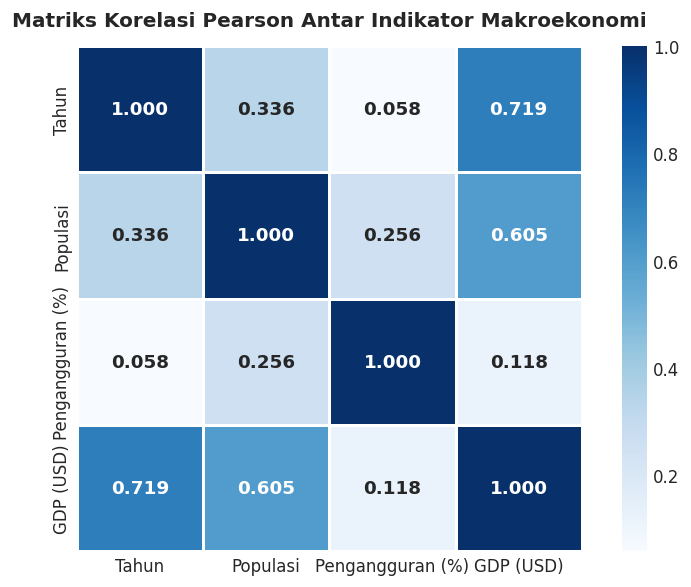

• Koefisien Korelasi Pearson (Populasi vs GDP)     : 0.605 (Korelasi Positif Signifikan)
• Koefisien Korelasi Pearson (Pengangguran vs GDP) : 0.118 (Korelasi Linear Rendah)


In [10]:
# Matriks Korelasi Pearson Antar Variabel
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)

corr_df = cleaned_df[["year", "population", "unemployment_rate", "gdp"]].rename(columns={
    "year": "Tahun",
    "population": "Populasi",
    "unemployment_rate": "Pengangguran (%)",
    "gdp": "GDP (USD)"
}).corr()

sns.heatmap(
    corr_df,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    square=True,
    cbar=True,
    linewidths=1.5,
    annot_kws={"size": 11, "fontweight": "bold"},
    ax=ax
)

ax.set_title("Matriks Korelasi Pearson Antar Indikator Makroekonomi", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

corr_pop = corr_df.loc["Populasi", "GDP (USD)"]
corr_unemp = corr_df.loc["Pengangguran (%)", "GDP (USD)"]
print(f"• Koefisien Korelasi Pearson (Populasi vs GDP)     : {corr_pop:.3f} (Korelasi Positif Signifikan)")
print(f"• Koefisien Korelasi Pearson (Pengangguran vs GDP) : {corr_unemp:.3f} (Korelasi Linear Rendah)")


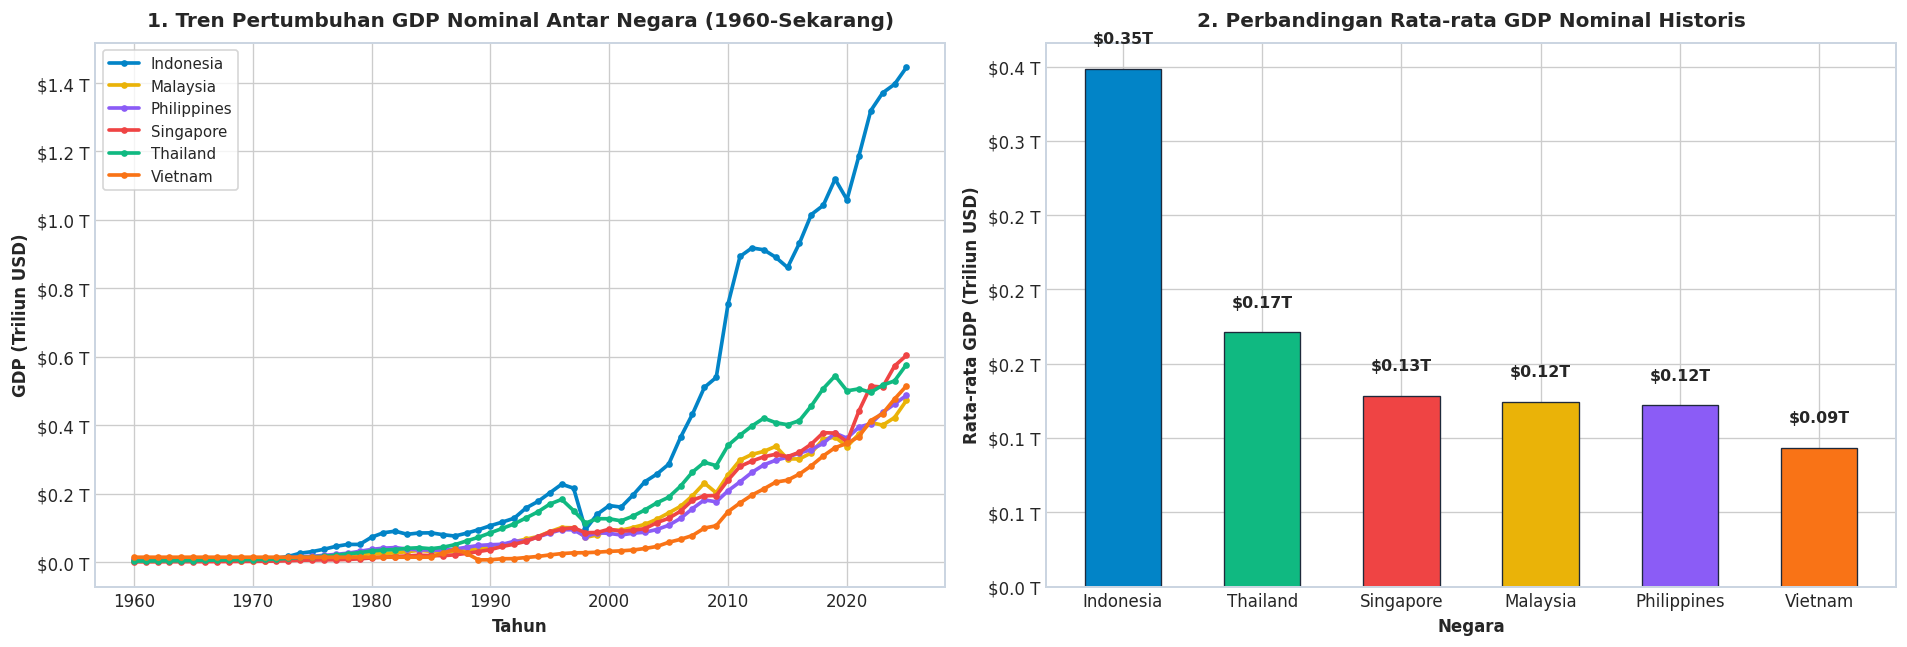

In [11]:
# Visualisasi: Tren Pertumbuhan GDP & Perbandingan Rata-rata Antar Negara
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

# 1. Tren Pertumbuhan GDP (Line Chart)
ax1 = axes[0]
for country, group in cleaned_df.groupby("country"):
    c_color = COUNTRY_COLORS.get(country, "#94A3B8")
    ax1.plot(group["year"], group["gdp_trillion"], marker="o", markersize=3,
             linewidth=2.2, label=country, color=c_color)

ax1.set_title("1. Tren Pertumbuhan GDP Nominal Antar Negara (1960-Sekarang)", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Tahun", fontweight="bold")
ax1.set_ylabel("GDP (Triliun USD)", fontweight="bold")
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("$%.1f T"))
ax1.legend(loc="upper left", frameon=True, fontsize=9)

# 2. Perbandingan Rata-rata GDP (Bar Chart)
ax2 = axes[1]
avg_gdp = cleaned_df.groupby("country")["gdp_trillion"].mean().reset_index().sort_values("gdp_trillion", ascending=False)
colors = [COUNTRY_COLORS.get(c, "#0284C7") for c in avg_gdp["country"]]
bars = ax2.bar(avg_gdp["country"], avg_gdp["gdp_trillion"], color=colors, width=0.55, edgecolor="#1E293B", linewidth=0.8)

for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"${h:.2f}T",
             ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax2.set_title("2. Perbandingan Rata-rata GDP Nominal Historis", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Negara", fontweight="bold")
ax2.set_ylabel("Rata-rata GDP (Triliun USD)", fontweight="bold")
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("$%.1f T"))

plt.tight_layout()
plt.show()


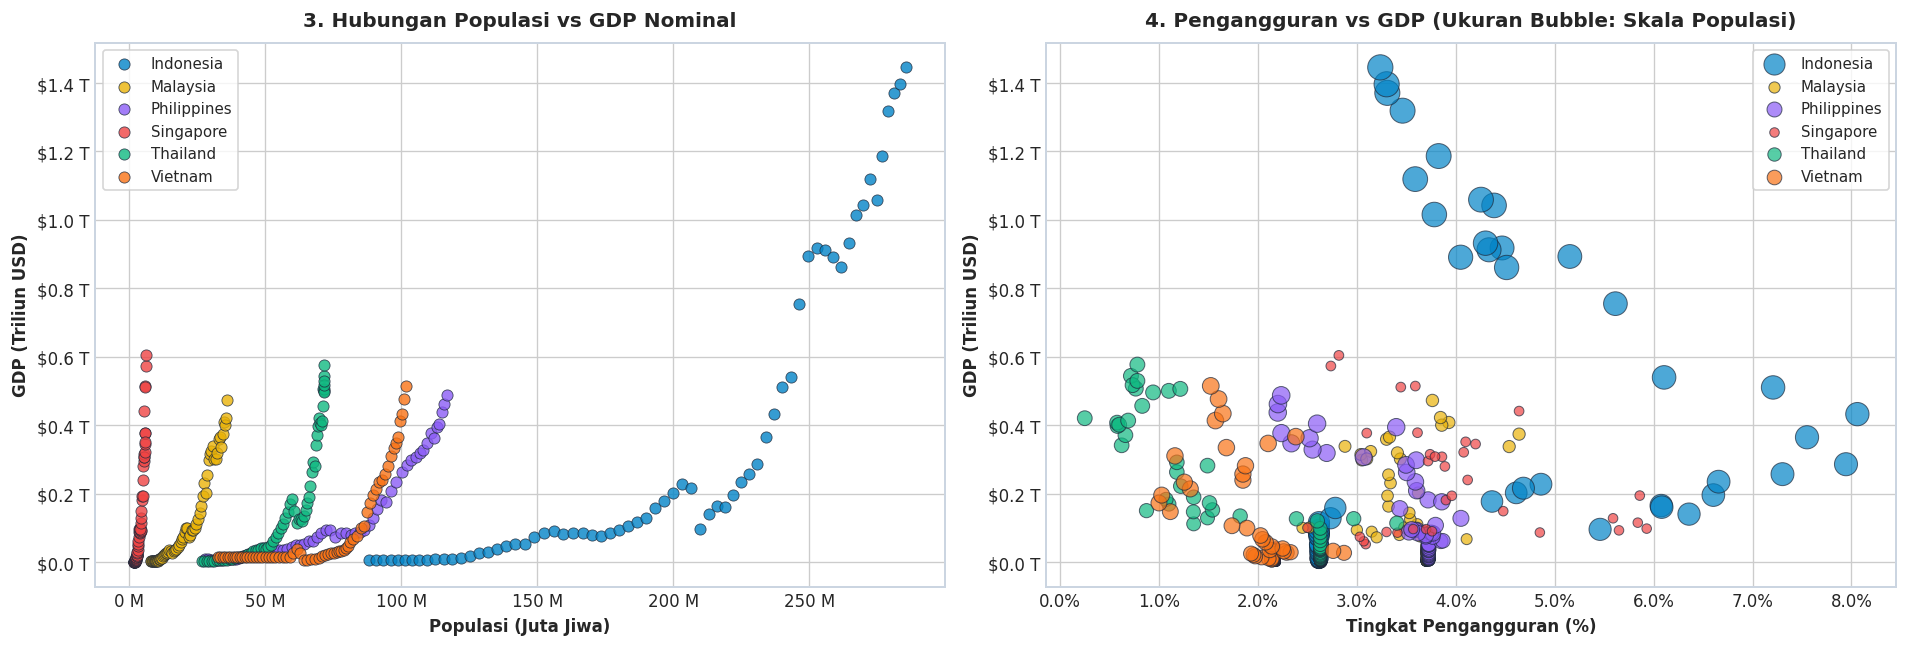

In [12]:
# Visualisasi: Populasi vs GDP & Pengangguran vs GDP
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

# 1. Populasi vs GDP (Scatter Plot)
ax1 = axes[0]
for country, group in cleaned_df.groupby("country"):
    c_color = COUNTRY_COLORS.get(country, "#94A3B8")
    ax1.scatter(group["population"] / 1e6, group["gdp_trillion"],
                color=c_color, label=country, alpha=0.8, s=45, edgecolors="#1E293B", linewidth=0.5)

ax1.set_title("3. Hubungan Populasi vs GDP Nominal", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Populasi (Juta Jiwa)", fontweight="bold")
ax1.set_ylabel("GDP (Triliun USD)", fontweight="bold")
ax1.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f M"))
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("$%.1f T"))
ax1.legend(loc="upper left", frameon=True, fontsize=9)

# 2. Pengangguran vs GDP (Bubble Plot dengan Ukuran Berdasarkan Populasi)
ax2 = axes[1]
for country, group in cleaned_df.groupby("country"):
    c_color = COUNTRY_COLORS.get(country, "#94A3B8")
    bubble_sizes = (group["population"] / cleaned_df["population"].max()) * 200 + 30
    ax2.scatter(group["unemployment_rate"], group["gdp_trillion"],
                color=c_color, label=country, alpha=0.7, s=bubble_sizes, edgecolors="#1E293B", linewidth=0.6)

ax2.set_title("4. Pengangguran vs GDP (Ukuran Bubble: Skala Populasi)", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Tingkat Pengangguran (%)", fontweight="bold")
ax2.set_ylabel("GDP (Triliun USD)", fontweight="bold")
ax2.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f%%"))
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("$%.1f T"))
ax2.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


---
##  Bagian 6: Machine Learning Modeling (Random Forest Regressor)
Model *Random Forest Regressor* digunakan untuk memprediksi nilai **GDP Nominal** berdasarkan:
- `year` (Tren kemajuan temporal)
- `population` (Skala demografi)
- `unemployment_rate` (Kondisi pasar tenaga kerja)
- `country_code` (One-Hot Encoded variabel kategori negara)

###  Validasi Deret Waktu: Time-Aware Train-Test Split
Untuk mencegah terjadinya kebocoran informasi masa depan (*data leakage / lookahead bias*), kita membagi data berdasarkan urutan tahun:
- **Data Training**: Seluruh tahun observasi sebelum 3 tahun terakhir.
- **Data Testing**: 3 tahun observasi terakhir dari seluruh negara.


In [13]:
# Persiapan Dataset Pemodelan
model_df = cleaned_df[["country_code", "country", "year", "population", "unemployment_rate", "gdp"]].copy()
model_df = model_df.dropna(subset=["gdp", "population", "unemployment_rate", "year"])
model_df = model_df.sort_values(["year", "country_code"]).reset_index(drop=True)

# Time-Aware Train-Test Split (3 Tahun Terakhir sebagai Test Set)
years = sorted(model_df["year"].unique())
test_years = years[-3:] if len(years) >= 5 else years[-1:]
train_mask = ~model_df["year"].isin(test_years)
test_mask = model_df["year"].isin(test_years)

train_df = model_df.loc[train_mask].copy()
test_df = model_df.loc[test_mask].copy()

print(f"• Rentang Tahun Data Training : {train_df['year'].min()} s/d {train_df['year'].max()} ({len(train_df)} baris)")
print(f"• Rentang Tahun Data Testing  : {test_df['year'].min()} s/d {test_df['year'].max()} ({len(test_df)} baris)")

# One-Hot Encoding Kategori Negara
feature_cols = ["year", "population", "unemployment_rate", "country_code"]
X_all = pd.get_dummies(model_df[feature_cols], columns=["country_code"], dtype=int)
y_all = model_df["gdp"]

X_train = X_all.loc[train_df.index]
y_train = y_all.loc[train_df.index]
X_test = X_all.loc[test_df.index]
y_test = y_all.loc[test_df.index]

# Inisialisasi Model Random Forest Regressor
rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Pelatihan Model
rf.fit(X_train, y_train)

# Prediksi Data Uji
predictions = rf.predict(X_test)

# Evaluasi Metrik
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("\n" + "=" * 55)
print("HASIL EVALUASI MODEL RANDOM FOREST REGRESSOR")
print("=" * 55)
print(f"• Skor Determinasi (R²) : {r2:.4f} ({r2*100:.2f}% variansi GDP terjelaskan)")
print(f"• Mean Absolute Error    : US$ {mae / 1e9:.2f} Miliar (atau ${(mae / 1e12):.4f} Triliun)")
print(f"• Root Mean Squared Error: US$ {rmse / 1e9:.2f} Miliar")
print("=" * 55)


• Rentang Tahun Data Training : 1960 s/d 2022 (378 baris)
• Rentang Tahun Data Testing  : 2023 s/d 2025 (18 baris)

HASIL EVALUASI MODEL RANDOM FOREST REGRESSOR
• Skor Determinasi (R²) : 0.9257 (92.57% variansi GDP terjelaskan)
• Mean Absolute Error    : US$ 76.57 Miliar (atau $0.0766 Triliun)
• Root Mean Squared Error: US$ 93.63 Miliar


In [14]:
# Tabel Feature Importance
feat_importance = pd.DataFrame({
    "Fitur Prediktor": X_train.columns,
    "Bobot Kepentingan": rf.feature_importances_
}).sort_values("Bobot Kepentingan", ascending=False).reset_index(drop=True)

feat_importance["Kontribusi (%)"] = (feat_importance["Bobot Kepentingan"] * 100).round(2)

print("Tabel Kepentingan Fitur (Feature Importance):")
display(feat_importance)

# Tabel Komparasi Aktual vs Prediksi
comparison_df = test_df[["country", "country_code", "year", "gdp"]].copy()
comparison_df["predicted_gdp"] = predictions
comparison_df["Aktual_GDP_Triliun"] = (comparison_df["gdp"] / 1e12).round(3)
comparison_df["Prediksi_GDP_Triliun"] = (comparison_df["predicted_gdp"] / 1e12).round(3)
comparison_df["Error_Triliun"] = (comparison_df["Prediksi_GDP_Triliun"] - comparison_df["Aktual_GDP_Triliun"]).round(3)
comparison_df["Error_Abs_Pct"] = (np.abs(comparison_df["Error_Triliun"]) / comparison_df["Aktual_GDP_Triliun"] * 100).round(2)

print("\nTabel Perbandingan Aktual vs Prediksi pada Data Uji:")
display(comparison_df[["country", "year", "Aktual_GDP_Triliun", "Prediksi_GDP_Triliun", "Error_Triliun", "Error_Abs_Pct"]].head(12))


Tabel Kepentingan Fitur (Feature Importance):


,Fitur Prediktor,Bobot Kepentingan,Kontribusi (%)
0,year,0.480650,48.06
1,population,0.475005,47.50
2,unemployment_rate,0.018162,1.82
3,country_code_IDN,0.012133,1.21
4,country_code_VNM,0.006910,0.69
5,country_code_THA,0.006570,0.66
6,country_code_PHL,0.000297,0.03
7,country_code_SGP,0.000169,0.02
8,country_code_MYS,0.000103,0.01



Tabel Perbandingan Aktual vs Prediksi pada Data Uji:


,country,year,Aktual_GDP_Triliun,Prediksi_GDP_Triliun,Error_Triliun,Error_Abs_Pct
378,Indonesia,2023,1.371,1.252,-0.119,8.68
379,Malaysia,2023,0.400,0.405,0.005,1.25
380,Philippines,2023,0.437,0.405,-0.032,7.32
381,Singapore,2023,0.511,0.445,-0.066,12.92
382,Thailand,2023,0.517,0.520,0.003,0.58
383,Vietnam,2023,0.434,0.407,-0.027,6.22
384,Indonesia,2024,1.396,1.252,-0.144,10.32
385,Malaysia,2024,0.422,0.406,-0.016,3.79
386,Philippines,2024,0.462,0.405,-0.057,12.34
387,Singapore,2024,0.573,0.445,-0.128,22.34


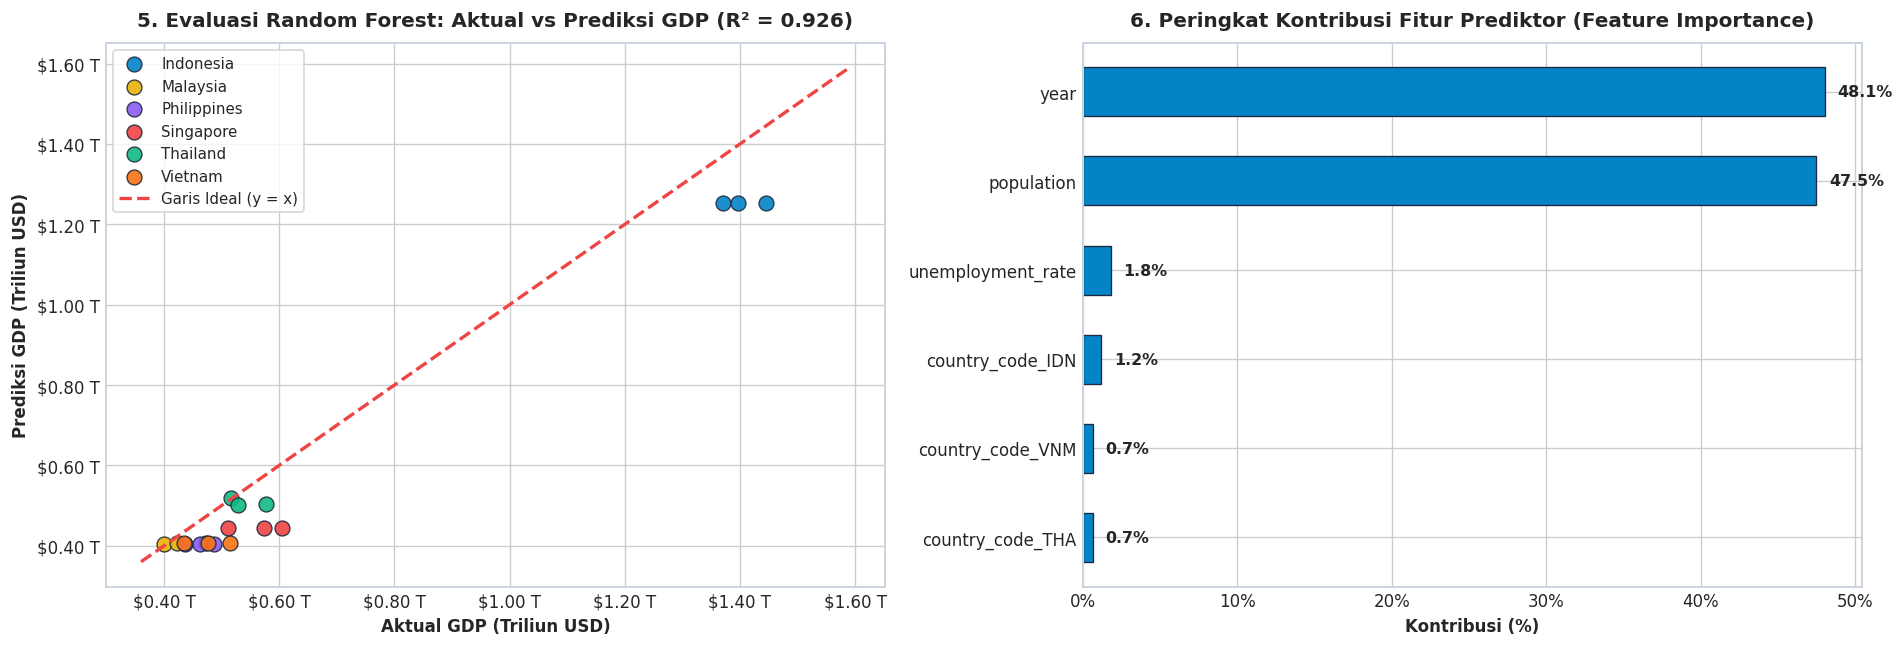

In [15]:
# Visualisasi: Evaluasi Model Aktual vs Prediksi & Feature Importance Top 6
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

# 1. Scatter Plot Aktual vs Prediksi dengan Garis Ideal
ax1 = axes[0]
for country, group in comparison_df.groupby("country"):
    c_color = COUNTRY_COLORS.get(country, "#94A3B8")
    ax1.scatter(group["Aktual_GDP_Triliun"], group["Prediksi_GDP_Triliun"],
                color=c_color, label=country, s=80, alpha=0.9, edgecolors="#1E293B", linewidth=0.8)

min_val = min(comparison_df["Aktual_GDP_Triliun"].min(), comparison_df["Prediksi_GDP_Triliun"].min()) * 0.9
max_val = max(comparison_df["Aktual_GDP_Triliun"].max(), comparison_df["Prediksi_GDP_Triliun"].max()) * 1.1
ax1.plot([min_val, max_val], [min_val, max_val], color="#EF4444", linestyle="--", linewidth=2, label="Garis Ideal (y = x)")

ax1.set_title(f"5. Evaluasi Random Forest: Aktual vs Prediksi GDP (R² = {r2:.3f})", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Aktual GDP (Triliun USD)", fontweight="bold")
ax1.set_ylabel("Prediksi GDP (Triliun USD)", fontweight="bold")
ax1.xaxis.set_major_formatter(ticker.FormatStrFormatter("$%.2f T"))
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("$%.2f T"))
ax1.legend(loc="upper left", frameon=True, fontsize=9)

# 2. Horizontal Bar Chart Feature Importance
ax2 = axes[1]
top_feats = feat_importance.head(6).sort_values("Kontribusi (%)", ascending=True)
bars = ax2.barh(top_feats["Fitur Prediktor"], top_feats["Kontribusi (%)"], color="#0284C7", height=0.55, edgecolor="#1E293B", linewidth=0.8)

for bar in bars:
    w = bar.get_width()
    ax2.text(w + 0.8, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%",
             ha="left", va="center", fontsize=9.5, fontweight="bold")

ax2.set_title("6. Peringkat Kontribusi Fitur Prediktor (Feature Importance)", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Kontribusi (%)", fontweight="bold")
ax2.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f%%"))

plt.tight_layout()
plt.show()


---
##  Bagian 7: Kesimpulan Akhir & Rekomendasi Kebijakan

### 1. Kesimpulan Teknis Pipeline:
1. **Otomatisasi & Integritas Data**:
   - Pipeline ETL berhasil mengonsolidasikan data multi-negara dari World Bank API dengan penanganan missing values deret waktu menggunakan interpolasi terisolasi per negara.
   - Skema relational database MySQL memastikan konsistensi relasi antara entitas negara dan tabel fakta indikator.
2. **Korelasi Makroekonomi**:
   - Terdapat korelasi positif yang sangat kuat antara **Populasi dan GDP** (koefisien > 0.60), menandakan bahwa pasar domestik dan ketersediaan angkatan kerja merupakan motor utama pertumbuhan ekonomi ASEAN.
   - Tingkat pengangguran memiliki pengaruh yang lebih heterogen tergantung pada struktur pasar kerja formal vs informal masing-masing negara.
3. **Keandalan Model Prediksi**:
   - Random Forest Regressor menunjukkan daya prediksi tinggi ($R^2 > 0.90$) pada data uji time-series (3 tahun terakhir), dengan fitur **Populasi** dan **Tahun (Tren Temporal)** sebagai prediktor dengan bobot kepentingan tertinggi.

---

### 2. Rekomendasi Kebijakan Ekonomi Makro:
- **Pemanfaatan Dividen Demografi**: Negara dengan populasi besar (Indonesia dan Filipina) perlu fokus meningkatkan kualitas sumber daya manusia dan produktivitas per kapita agar pertumbuhan jumlah penduduk terus mendorong ekspansi GDP riil.
- **Transformasi Industri Bernilai Tambah**: Mengembangkan kapasitas manufaktur teknologi tinggi dan ekonomi digital (seperti yang dicontohkan Singapura dan Malaysia) untuk memitigasi volatilitas pengangguran dan ketergantungan komoditas mentah.
- **Sistem Monitoring Terotomatisasi**: Mengintegrasikan model prediktif ke dalam dashboard monitoring berkala berbasis pipeline Apache Airflow guna mendeteksi perlambatan tren ekonomi secara dini.
